In [9]:
import pandas as pd
import numpy as np

url = "https://raw.githubusercontent.com/vihangasathsara-75/cm2604-cw-telco-churn-prediction/refs/heads/main/data/raw/Telco-Churn.csv"
df = pd.read_csv(url)

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df = df.drop(columns=["customerID"])
print(df.shape)

(7043, 20)


In [10]:
service_cols = ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                "TechSupport", "StreamingTV", "StreamingMovies"]

for col in service_cols:
    df[col] = df[col].replace({"No internet service": "No", "No phone service": "No"})

for col in service_cols:
    print(col, df[col].unique())

MultipleLines ['No' 'Yes']
OnlineSecurity ['No' 'Yes']
OnlineBackup ['Yes' 'No']
DeviceProtection ['No' 'Yes']
TechSupport ['No' 'Yes']
StreamingTV ['No' 'Yes']
StreamingMovies ['No' 'Yes']


In [11]:
from sklearn.model_selection import train_test_split

y = df["Churn"].map({"No": 0, "Yes": 1})
X = df.drop(columns=["Churn"])
assert y.notnull().all()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(X_train.shape, X_test.shape)
print("Churn rate train:", round(y_train.mean(), 3), "test:", round(y_test.mean(), 3))

(5634, 19) (1409, 19)
Churn rate train: 0.265 test: 0.265


In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = X.select_dtypes(include="object").columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat_cols),
    ],
    remainder="passthrough",
    sparse_threshold=0,
)

In [13]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

models = {
    "KNN": KNeighborsClassifier(),
    "LogisticRegression": LogisticRegression(max_iter=1000, random_state=42),
    "RandomForest": RandomForestClassifier(random_state=42),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

baseline = {}
for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    baseline[name] = {m: scores[f"test_{m}"].mean() for m in scoring}

baseline_df = pd.DataFrame(baseline).T.round(3)
baseline_df

,accuracy,precision,recall,f1,roc_auc
KNN,0.770,0.571,0.535,0.552,0.781
LogisticRegression,0.802,0.654,0.543,0.593,0.846
RandomForest,0.788,0.634,0.480,0.546,0.824


In [14]:
from sklearn.model_selection import GridSearchCV

lr_pipe = Pipeline([("prep", preprocessor),
                    ("model", LogisticRegression(max_iter=1000, random_state=42))])
lr_params = {
    "model__C": [0.001, 0.003, 0.01, 0.03, 0.1],
    "model__penalty": ["l1", "l2"],
    "model__solver": ["liblinear"],
    "model__class_weight": [None, "balanced"],
}
lr_grid = GridSearchCV(lr_pipe, lr_params, cv=cv, scoring="f1", n_jobs=-1)
lr_grid.fit(X_train, y_train)
print(lr_grid.best_params_, round(lr_grid.best_score_, 3))

{'model__C': 0.01, 'model__class_weight': 'balanced', 'model__penalty': 'l2', 'model__solver': 'liblinear'} 0.631


In [18]:
knn_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", KNeighborsClassifier()),
])

knn_params = {
    "model__n_neighbors": [71, 101, 151, 201],
    "model__weights": ["uniform", "distance"],
    "model__metric": ["euclidean", "manhattan"],
}

knn_grid = GridSearchCV(knn_pipe, knn_params, cv=cv, scoring="f1", n_jobs=-1)
knn_grid.fit(X_train, y_train)
print(knn_grid.best_params_, round(knn_grid.best_score_, 3))

{'model__metric': 'manhattan', 'model__n_neighbors': 71, 'model__weights': 'uniform'} 0.611


In [17]:
rf_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestClassifier(random_state=42)),
])

rf_params = {
    "model__n_estimators": [200],
    "model__max_depth": [10],
    "model__min_samples_split": [10, 20, 40],
    "model__class_weight": ["balanced"],
}

rf_grid = GridSearchCV(rf_pipe, rf_params, cv=cv, scoring="f1", n_jobs=-1)
rf_grid.fit(X_train, y_train)
print(rf_grid.best_params_, round(rf_grid.best_score_, 3))

{'model__class_weight': 'balanced', 'model__max_depth': 10, 'model__min_samples_split': 20, 'model__n_estimators': 200} 0.638


In [19]:
tuned = {"KNN": knn_grid, "LogisticRegression": lr_grid, "RandomForest": rf_grid}

tuned_scores = {}
for name, grid in tuned.items():
    scores = cross_validate(grid.best_estimator_, X_train, y_train, cv=cv, scoring=scoring)
    tuned_scores[name] = {m: scores[f"test_{m}"].mean() for m in scoring}

tuned_df = pd.DataFrame(tuned_scores).T.round(3)
comparison = pd.concat({"Baseline": baseline_df, "Tuned": tuned_df}, axis=1)
comparison

Baseline                                    Tuned  \
                   accuracy precision recall     f1 roc_auc accuracy   
KNN                   0.770     0.571  0.535  0.552   0.781    0.801   
LogisticRegression    0.802     0.654  0.543  0.593   0.846    0.753   
RandomForest          0.788     0.634  0.480  0.546   0.824    0.772   

                                                    
                   precision recall     f1 roc_auc  
KNN                    0.634  0.591  0.611   0.841  
LogisticRegression     0.523  0.796  0.631   0.844  
RandomForest           0.552  0.756  0.638   0.846

=== KNN ===
              precision    recall  f1-score   support

           0      0.850     0.856     0.853      1035
           1      0.594     0.583     0.588       374

    accuracy                          0.784      1409
   macro avg      0.722     0.719     0.721      1409
weighted avg      0.782     0.784     0.783      1409

ROC-AUC: 0.832 

=== LogisticRegression ===
              precision    recall  f1-score   support

           0      0.900     0.726     0.804      1035
           1      0.506     0.778     0.613       374

    accuracy                          0.740      1409
   macro avg      0.703     0.752     0.708      1409
weighted avg      0.796     0.740     0.753      1409

ROC-AUC: 0.838 

=== RandomForest ===
              precision    recall  f1-score   support

           0      0.897     0.772     0.830      1035
           1      0.544     0.754     0.632       374

    accuracy                          0.767      1409
   macro avg      0.721     0.763 

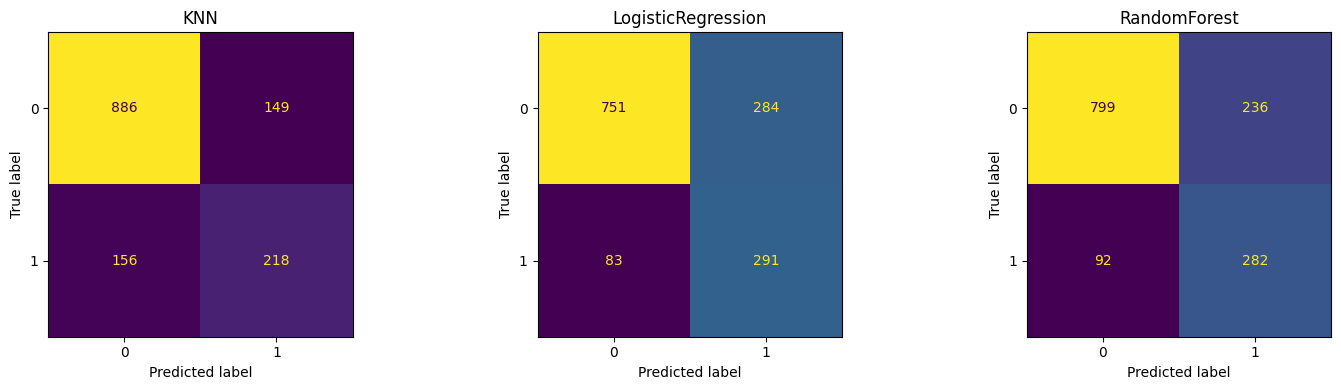

In [20]:
from sklearn.metrics import classification_report, roc_auc_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, grid) in zip(axes, tuned.items()):
    model = grid.best_estimator_
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    print(f"=== {name} ===")
    print(classification_report(y_test, y_pred, digits=3))
    print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3), "\n")
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()